# Weekly shop sales: from forecast to stock order

**A forecast earns its keep through the decision it feeds. Here that decision is how many units to order.**

An online gift shop restocks 30 of its steady sellers every four weeks. Order too little and customers find the product sold out. Order too much and the money sits on a shelf. We start with the usual recipe, a regression on the last 12 weeks of sales, and find that it does worse than the plain average of everything sold so far. TimeGym's scorecard shows why, and points to a simpler forecaster that fits what these products do. We confirm it on the shop's own history, turn both forecasts into stock orders to see what the difference is worth, look at what neither model can do, and leave a test behind that stops a later change from undoing the work.

*Data: two years of orders from a UK online gift shop, summed into units per product and week, from the UCI Machine Learning Repository, CC BY 4.0 ([source and license](data/README.md#store-sales)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import tempfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression

from timegym import LastValueForecaster, NaiveForecaster, Pipeline, cases_from_series

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Two years of a gift shop

`load` returns one column per product and one row per week, counted in units sold. Weeks start on Monday.

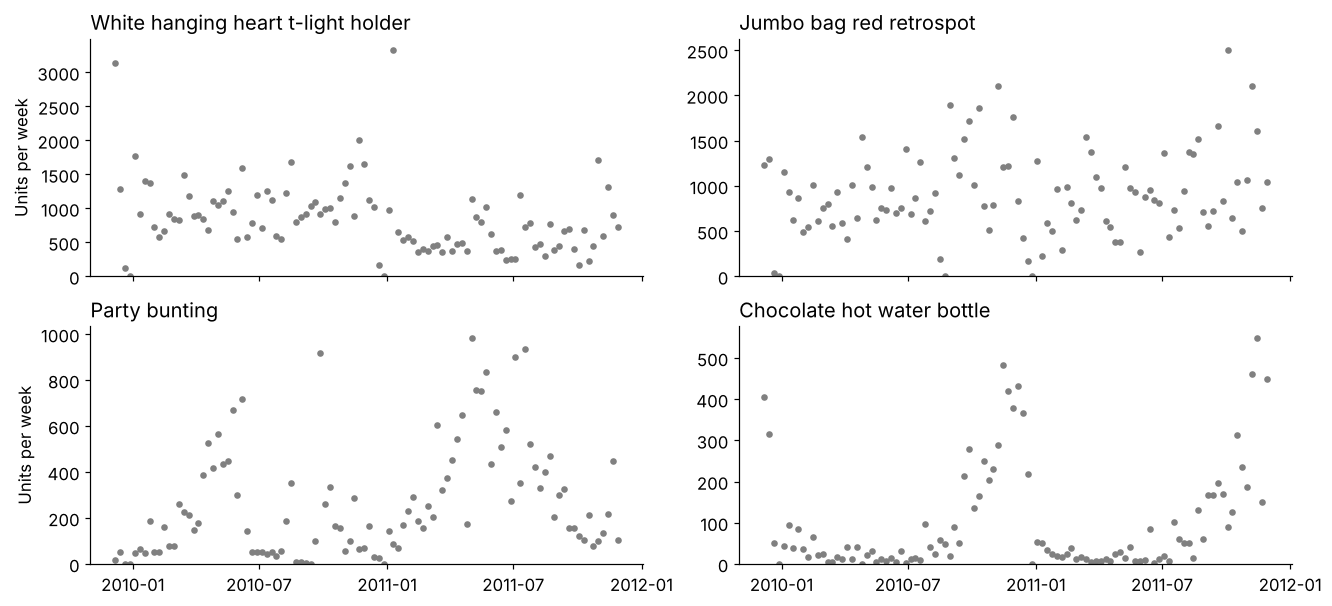

30 products, 104 weeks from 07 December 2009 to 28 November 2011.
A typical product sells 287 units a week, and its sales change by 58% of that from one week to the next.


In [2]:
sales = load("store-sales").astype(float)
shown = ["White hanging heart t-light holder", "Jumbo bag red retrospot",
         "Party bunting", "Chocolate hot water bottle"]
fig, axes = plt.subplots(2, 2, figsize=(12, 5.4), sharex=True, layout="constrained")
for ax, product in zip(axes.flat, shown):
    ax.scatter(sales.index, sales[product], color="0.5", s=11)
    ax.set(title=product, ylim=(0, None))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
for ax in axes[:, 0]:
    ax.set_ylabel("Units per week")
plt.show()
print(f"{sales.shape[1]} products, {len(sales)} weeks from {sales.index[0]:%d %B %Y} to {sales.index[-1]:%d %B %Y}.")
print(f"A typical product sells {sales.mean().median():.0f} units a week, and its sales change by "
      f"{(sales.diff().abs().mean() / sales.mean()).median():.0%} of that from one week to the next.")

The series are noisy: single large orders show as spikes, some products come and go with the seasons, and the shop closes for a week after Christmas, which shows as a zero.

## The usual recipe, tested the usual way

Every four weeks we forecast the next four weeks of each product. We replay that through the second year: 13 forecast dates, 30 products, 390 forecasts in all. Each forecast is made from that product's history up to its date, and `cases_from_series` cuts those cases for us.

Three forecasters to start with:

- **Linear on 12 weeks**: a linear regression that predicts each week from the 12 before it. The usual first model.
- **Last week**: next month looks like last week.
- **Average of all history**: next month looks like the average week so far.

To put large and small products on one scale, we score each forecast by its average weekly miss divided by that product's usual week-to-week change. TimeGym records this for every forecast as `mase`. Lower is better.

In [3]:
weeks_ahead = 4
history_lengths = range(52, len(sales) - weeks_ahead + 1, 4)   # every four weeks, once a year of history exists
cases = [case for product in sales.columns
         for case in cases_from_series(sales[[product]], origins=history_lengths, horizon=weeks_ahead, name=product)]


def backtest(name, pipeline):
    "Forecast every case. One row per forecast: its scaled miss, the forecast total and the units sold."
    run = pipeline.run(cases=cases, keep_data=True)
    assert run.report.summary["status_counts"]["FAIL"] == 0   # every forecast passed the output checks
    return pd.DataFrame([{"model": name, "product": entry.case.manifest["kind"],
                          "forecast from": entry.case.task.future_index[0],
                          "miss": entry.result.metrics["mase"],
                          "forecast": entry.forecast.point.sum(),
                          "sold": entry.case.observed.to_numpy().sum()} for entry in run.cases])


linear = Pipeline(LinearRegression(), window_length=12)
results = pd.concat([backtest("Linear on 12 weeks", linear),
                     backtest("Last week", Pipeline(LastValueForecaster())),
                     backtest("Average of all history", Pipeline(NaiveForecaster(strategy="mean")))])
average_miss = results.groupby("model", sort=False)["miss"].mean()
display(average_miss.round(2).to_frame("average scaled miss"))
print(f"{len(cases)} forecasts per model, from {results['forecast from'].min():%d %B %Y} "
      f"to {results['forecast from'].max():%d %B %Y}.")
assert average_miss["Linear on 12 weeks"] > average_miss["Average of all history"]

,average scaled miss
model,
Linear on 12 weeks,1.07
Last week,1.05
Average of all history,0.96


390 forecasts per model, from 06 December 2010 to 07 November 2011.


The regression comes last. It is slightly worse than repeating last week, and clearly worse than the average of all history, a forecaster with nothing to fit. Something about these series does not suit it.

## Why: the scorecard, at the shape of our task

A backtest says that a model lost, not why. The scorecard runs the model on generated series of ten known kinds, where TimeGym knows the best possible forecast, and names the mistakes it makes on each kind. We ask for it at the shape of our task: 76 weeks of history, which is the middle of what our backtest had, forecasting 4 weeks ahead, with 30 series per cell.

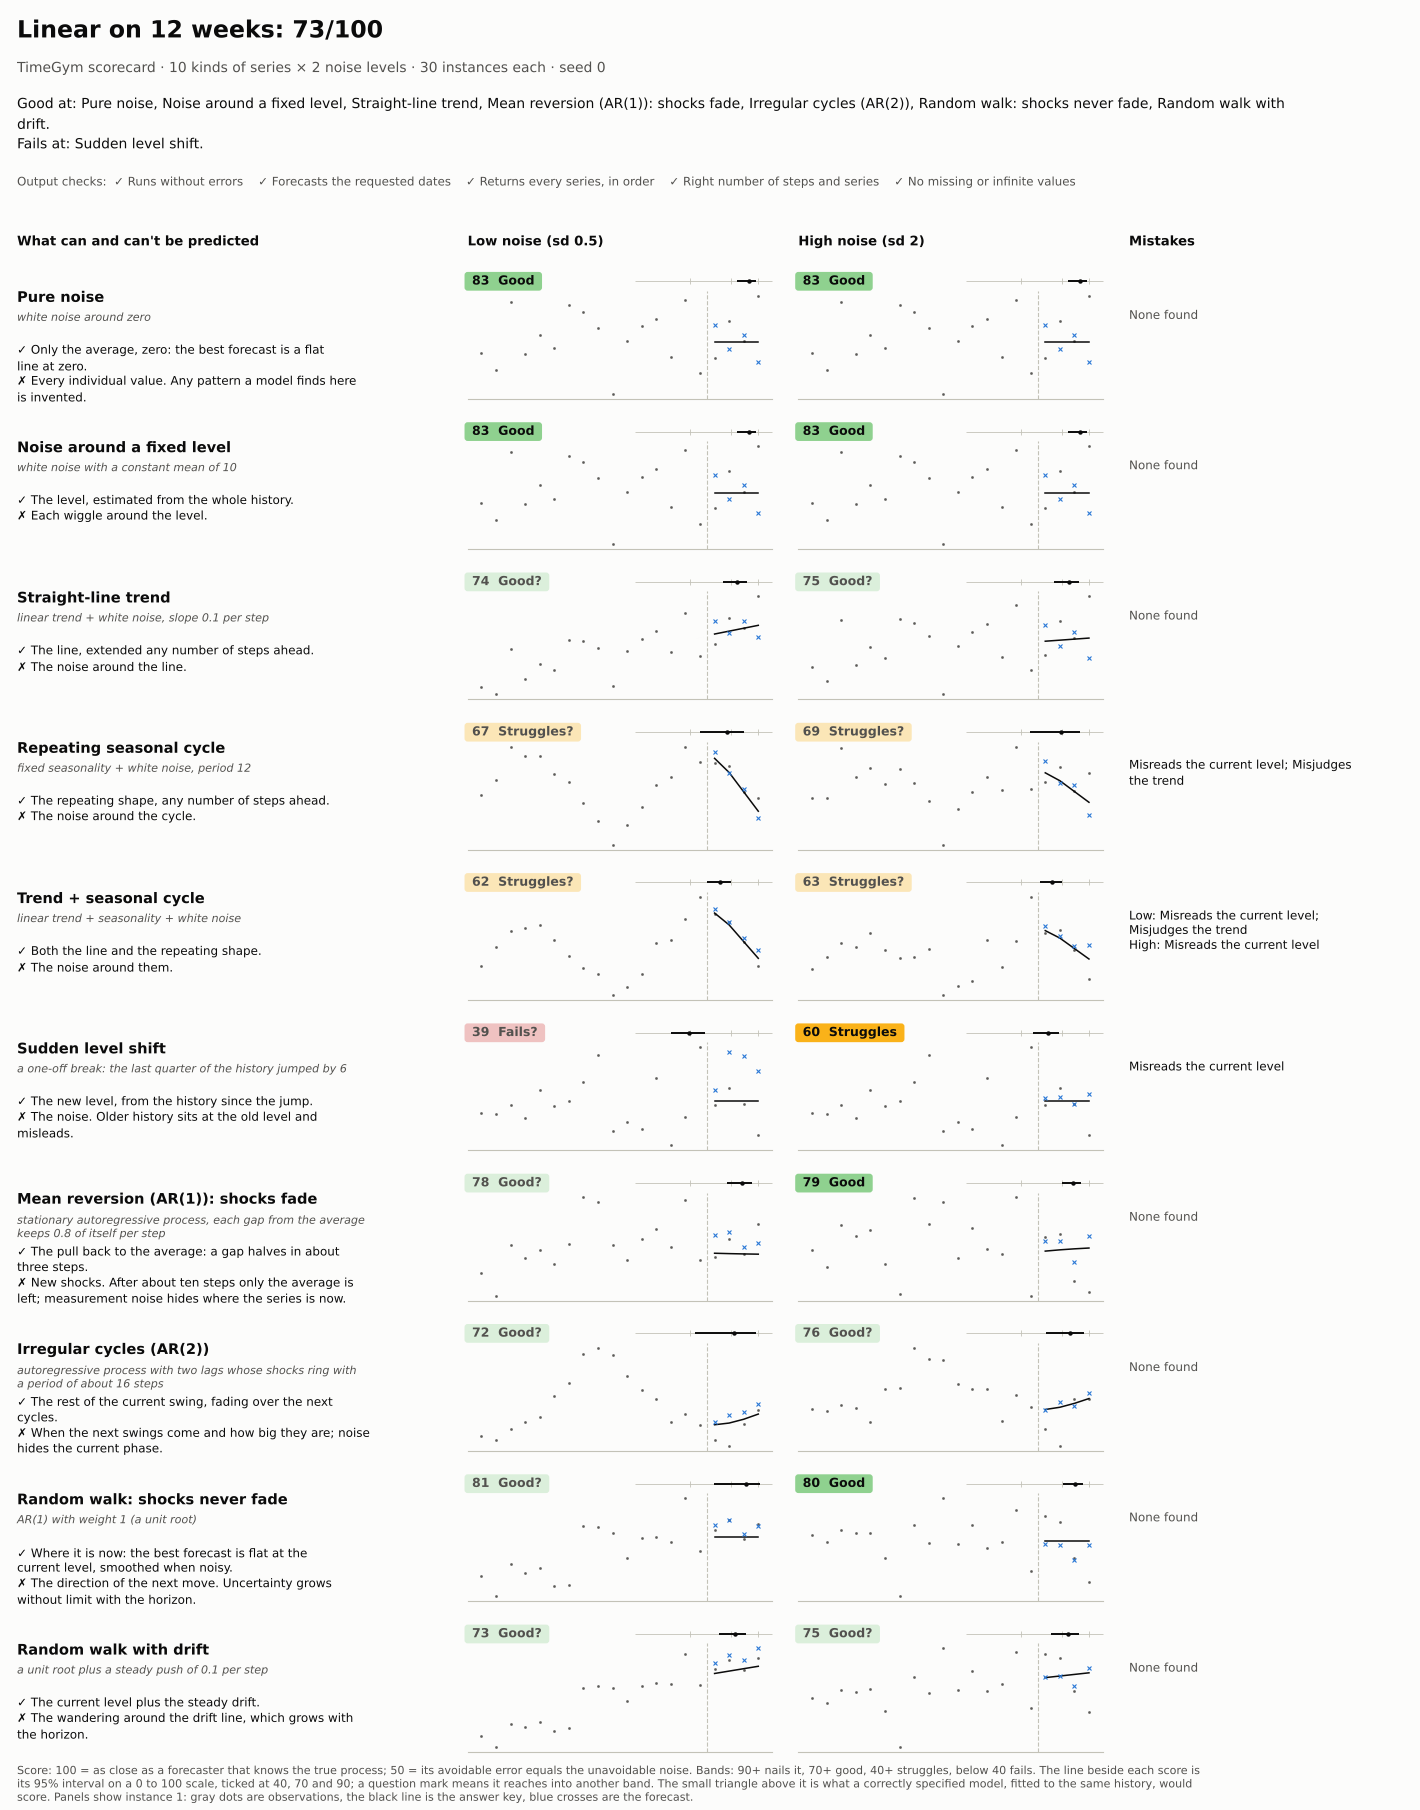

In [4]:
task_shape = dict(context_length=76, horizon=4, instances=30)
linear_card = linear.run(title="Linear on 12 weeks", **task_shape).scorecard
linear_card

The regression scores 73. No row is excellent. Even on the easiest kind of series, noise around a fixed level, it scores 83, where a plain average would be in the high 90s. It has 13 numbers to estimate from 64 examples, and each of them picks up some noise. After a sudden level shift, which is what a product does when it catches on or goes out of fashion, it is the worst row on the card, with the mistake "Misreads the current level". (A question mark means 30 series were not enough to settle that verdict.)

Our products are mostly a level that wanders, sometimes jumps, and carries a lot of noise. So we want a forecaster that is strong on those rows, and we can do without the ability to learn a repeating shape from 12 weeks of inputs.

## A forecaster that fits the products

Exponential smoothing keeps a running average that weights recent weeks more, and forecasts that level. It has one number to choose: how fast to forget. TimeGym accepts any object with `fit(history)` and `predict(dates)`, so we write it in a few lines.

In [5]:
class Smoothing:
    "A running average that weights recent weeks more; the forgetting speed is picked on the history."

    def __init__(self, speeds=(0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9)):
        self.speeds = speeds

    def fit(self, history):
        values = history.to_numpy(dtype=float)[:, 0]
        best = None
        for speed in self.speeds:
            level, missed = values[0], 0.0
            for value in values[1:]:              # forecast each week from the level so far
                missed += (value - level) ** 2
                level += speed * (value - level)
            if best is None or missed < best[0]:
                best = (missed, level)
        self.level = best[1]
        return self

    def predict(self, dates):
        return np.full(len(dates), self.level)


smoothing = Pipeline(Smoothing())
smoothing_card = smoothing.run(title="Smoothing", **task_shape).scorecard

side_by_side = pd.DataFrame({
    "Kind of series": linear_card.table["title"], "Noise": linear_card.table["noise"],
    "Linear on 12 weeks": linear_card.table["score"], "Smoothing": smoothing_card.table["score"],
}).set_index(["Kind of series", "Noise"]).round(0).astype(int)
side_by_side.loc[("All kinds of series", "both"), :] = [round(linear_card.score), round(smoothing_card.score)]
display(side_by_side.astype(int))

smoothing_table = smoothing_card.table.set_index(["pattern", "noise"])
linear_table = linear_card.table.set_index(["pattern", "noise"])
for pattern in ("level", "level_shift", "random_walk"):   # the rows that look like our products
    assert (smoothing_table.loc[pattern, "score"] > linear_table.loc[pattern, "score"]).all()
assert smoothing_table.loc[("seasonal", "Low noise"), "score"] < 40   # and the price for it
assert smoothing_card.score < linear_card.score

Linear on 12 weeks  Smoothing
Kind of series                      Noise                                    
Pure noise                          Low noise                   83         95
                                    High noise                  83         95
Noise around a fixed level          Low noise                   83         95
                                    High noise                  83         95
Straight-line trend                 Low noise                   74         55
                                    High noise                  75         81
Repeating seasonal cycle            Low noise                   67          3
                                    High noise                  69         27
Trend + seasonal cycle              Low noise                   62          4
                                    High noise                  63         36
Sudden level shift                  Low noise                   39         59
                                    High noise                  60         84
Mean reversion (AR(1)): shocks fade Low noise                   78         76
                                    High noise                  79         87
Irregular cycles (AR(2))            Low noise                   72         25
                                    High noise                  76         41
Random walk: shocks never fade      Low noise                   81         99
                                    High noise                  80         98
Random walk with drift              Low noise                   73         91
                                    High noise                  75         93
All kinds of series                 both                        73         67

Read the bottom line first: smoothing has the lower total, 67 against 73. On totals alone we would keep the regression.

Then read the rows. On a fixed level, a level shift and a random walk, the rows that look like our products, smoothing is ahead every time: 95 against 83, 59 and 84 against 39 and 60, and 99 and 98 against 81 and 80. It loses its points on the seasonal cycle and the irregular cycles, where it scores between 3 and 41. A forecaster that only tracks a level cannot follow a repeating shape, and the card says so plainly. We come back to that below.

## Back to the shop's history

,average scaled miss
model,
Linear on 12 weeks,1.07
Last week,1.05
Average of all history,0.96
Smoothing,0.86


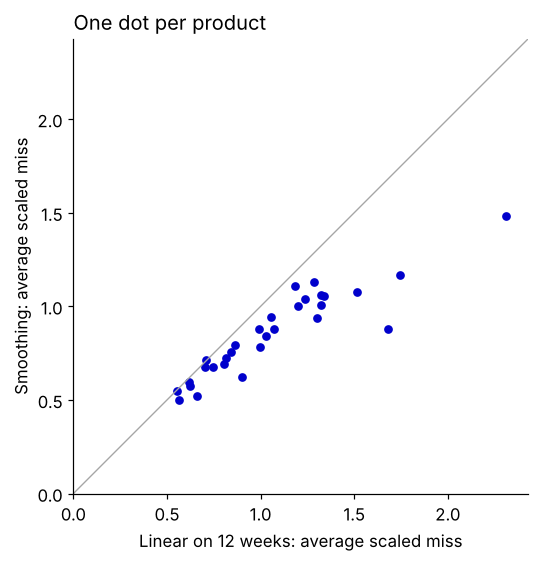

Smoothing has the smaller miss on 29 of 30 products (dots below the line).


In [6]:
results = pd.concat([results, backtest("Smoothing", smoothing)])
average_miss = results.groupby("model", sort=False)["miss"].mean()
display(average_miss.round(2).to_frame("average scaled miss"))

by_product = results.pivot_table(index="product", columns="model", values="miss")
better = int((by_product["Smoothing"] < by_product["Linear on 12 weeks"]).sum())
limit = by_product[["Smoothing", "Linear on 12 weeks"]].to_numpy().max() * 1.05
fig, ax = plt.subplots(figsize=(5.2, 5), layout="constrained")
ax.plot([0, limit], [0, limit], color="0.65", linewidth=0.9)
ax.scatter(by_product["Linear on 12 weeks"], by_product["Smoothing"], color="#0000CC", s=22)
ax.set(xlim=(0, limit), ylim=(0, limit), aspect="equal", title="One dot per product",
       xlabel="Linear on 12 weeks: average scaled miss", ylabel="Smoothing: average scaled miss")
plt.show()
print(f"Smoothing has the smaller miss on {better} of {len(by_product)} products (dots below the line).")
assert average_miss.idxmin() == "Smoothing" and better >= 27

Smoothing has the smallest average miss of the four, a fifth below the regression's, and it wins on 29 of the 30 products. The rows of the scorecard that looked like our products called it.

## What the difference is worth

A scaled miss means little to the person who places the orders. So we turn each forecast into an order, with a simple rule: stock for the next four weeks is the forecast total times a safety buffer. If more is sold than was stocked, the difference is units short. If less, it is leftover stock. A bigger buffer trades fewer units short for more leftover, so each forecaster gives a curve, and a better forecaster's curve lies lower.

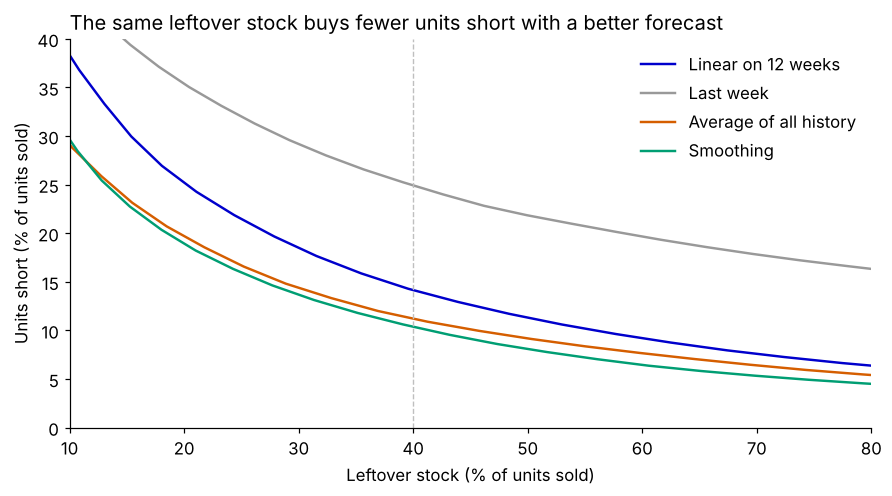

,units short (%) when leftover stock is 40% of sales
Linear on 12 weeks,14.1
Last week,24.9
Average of all history,11.2
Smoothing,10.4


In [7]:
buffers = np.arange(0.6, 2.01, 0.05)
colors = {"Linear on 12 weeks": "#0000CC", "Last week": "0.6", "Average of all history": "#D55E00", "Smoothing": "#009E73"}


def stock_curve(rows):
    "Leftover stock and units short, each as a percentage of units sold, for every buffer."
    stock = np.outer(buffers, rows["forecast"].clip(lower=0))
    sold = rows["sold"].to_numpy()
    return (100 * np.clip(stock - sold, 0, None).sum(axis=1) / sold.sum(),
            100 * np.clip(sold - stock, 0, None).sum(axis=1) / sold.sum())


fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
short_at_40 = {}
for name, rows in results.groupby("model", sort=False):
    leftover, short = stock_curve(rows)
    ax.plot(leftover, short, color=colors[name], linewidth=1.6, label=name)
    short_at_40[name] = float(np.interp(40, leftover, short))
ax.axvline(40, color="0.75", linestyle="--", linewidth=0.9)
ax.set(xlim=(10, 80), ylim=(0, 40), title="The same leftover stock buys fewer units short with a better forecast",
       xlabel="Leftover stock (% of units sold)", ylabel="Units short (% of units sold)")
ax.legend()
plt.show()
display(pd.Series(short_at_40).round(1).to_frame("units short (%) when leftover stock is 40% of sales"))
assert min(short_at_40, key=short_at_40.get) == "Smoothing"

Hold leftover stock at 40% of sales, and the regression leaves 14% of the units customers wanted out of stock. Smoothing leaves 10%. That is about a quarter fewer lost sales for the same money on the shelf, from a forecaster with one number to fit. The average of all history is close behind smoothing, and "last week" is far worse than either.

## What neither model can do

The scorecard gave smoothing 3 and 27 on the seasonal cycle. A gift shop has a season. The next plot shows, for each of the 13 forecast dates, the total forecast across all products divided by what was sold: 1 means spot on, 2 means twice too much.

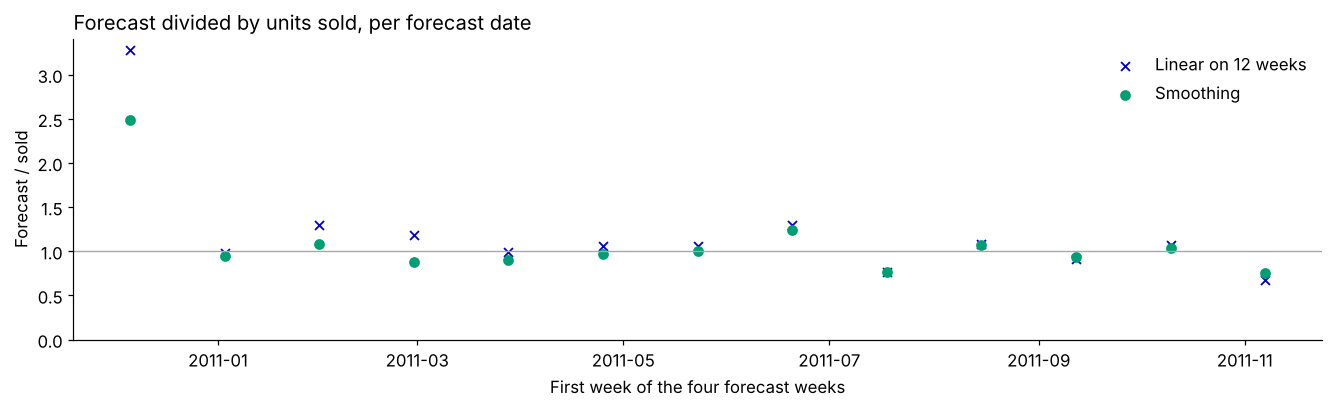

model,Linear on 12 weeks,Smoothing
forecast from,,
2010-12-06,3.28,2.48
2011-11-07,0.67,0.76


In [8]:
by_date = results.groupby(["model", "forecast from"])[["forecast", "sold"]].sum()
ratio = (by_date["forecast"] / by_date["sold"]).unstack("model")
fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
ax.axhline(1, color="0.65", linewidth=0.9)
for name, marker in (("Linear on 12 weeks", "x"), ("Smoothing", "o")):
    ax.scatter(ratio.index, ratio[name], marker=marker, s=34, color=colors[name], linewidths=1.2, label=name)
ax.set(title="Forecast divided by units sold, per forecast date", xlabel="First week of the four forecast weeks",
       ylabel="Forecast / sold", ylim=(0, None))
ax.legend()
plt.show()
display(ratio.loc[[ratio.index[0], ratio.index[-1]], ["Linear on 12 weeks", "Smoothing"]].round(2))
assert ratio["Smoothing"].iloc[0] > 2 and ratio["Smoothing"].iloc[-1] < 0.85

Through most of the year smoothing stays within a quarter of what sold, and the regression within a third. At the two ends they are far off. Forecasting December 2010 from the end of November, both ordered well over twice what sold: sales fall away after the Christmas peak, and the shop then closes for a week. Forecasting November 2011 from October, both came in a quarter to a third too low, because the peak was building.

No model in this notebook knows about Christmas, and with two years of history, none could have learned it: each has seen at most one. The scorecard told us smoothing cannot follow a season. It took the backtest to show how much that costs here, and a planner would correct those weeks by hand until a third year of data exists.

## Keep it that way

The forecaster is chosen. The remaining risk is a later change that quietly makes it worse. `save_baseline` writes the scorecard's numbers to a small file, and `compare` checks a new version against it on exactly the same series. In a project the file lives next to the tests; here we use a temporary folder.

Suppose a colleague wants the forecast to react faster to this week's sales and fixes the forgetting speed at 0.5.

In [9]:
with tempfile.TemporaryDirectory() as folder:
    baseline_file = smoothing_card.save_baseline(Path(folder) / "smoothing-baseline.json")
    faster = Pipeline(Smoothing(speeds=(0.5,)))
    comparison = faster.run(title="Smoothing, fixed speed", **task_shape).scorecard.compare(baseline_file)

try:
    comparison.assert_no_regression()
except AssertionError as problem:
    print(problem)

faster_miss = backtest("Smoothing, fixed speed", faster)["miss"].mean()
print(f"\nOn the shop's history: average scaled miss {faster_miss:.2f}, against {average_miss['Smoothing']:.2f} before.")
assert len(comparison.worse) > 0 and faster_miss > average_miss["Smoothing"]

Worse than smoothing-baseline.json in 7 cells (30 series per cell, alpha 0.05):
  Pure noise, low noise: avoidable error 0.0120 -> 0.113 (+844%), p = 0.0001
  Pure noise, high noise: avoidable error 0.191 -> 1.81 (+844%), p = 0.0001
  Noise around a fixed level, low noise: avoidable error 0.0120 -> 0.113 (+844%), p = 0.0001
  Noise around a fixed level, high noise: avoidable error 0.191 -> 1.81 (+844%), p = 0.0001
  Sudden level shift, high noise: avoidable error 0.744 -> 1.40 (+88%), p = 0.0002
  Random walk: shocks never fade, high noise: avoidable error 0.122 -> 0.532 (+336%), p = 0.0001
  Random walk with drift, low noise: avoidable error 0.0984 -> 0.173 (+76%), p = 0.0017



On the shop's history: average scaled miss 0.88, against 0.86 before.


The check fails and names the cells: the faster version is worse on plain noise, a fixed level and a noisy random walk, because it chases every wobble. The shop's history agrees, by a smaller margin. In a test suite, that `assert_no_regression()` line is all it takes to stop the change before it reaches an order.

## What TimeGym added

- A backtest of 390 forecasts in a few lines, each made only from the history before its date, with every forecast checked for the right dates and finite values.
- A reason for the result. The scorecard explained why the regression struggles on these products, and its rows picked the replacement, against its own bottom line.
- A warning with a name: smoothing cannot follow a season. The backtest then showed where that bites.
- A test that keeps the choice from being undone.

## Change one thing

- Give the regression an easier job: `Pipeline(LinearRegression(), window_length=4)`. Does its scorecard improve on the fixed level, and does it catch up in the backtest?
- Ask what more history would buy: `linear.run(["level"], context_length=300, horizon=4).scorecard`.
- Order every two weeks: set `weeks_ahead = 2` and run the notebook again.
- Run it on every product the shop sells: `load("store-sales", full=True)` downloads the source once and returns 4,669 of them. Many sell in only a few weeks, which is a different problem.

**What this doesn't show.** The 13 forecast dates all come from one year of one shop, so they are not 13 independent tests. The stock rule is a simplification: real stock carries over from one month to the next, comes in pack sizes and takes time to arrive. The scorecard's seasonal cycle repeats every 12 steps; a yearly cycle in weekly data repeats every 52, and the grid has no such row. And we compared four simple forecasters, not everything one could try.

**Related:** [Custom model](../tutorials/02_custom_model.ipynb) shows what a forecaster of your own needs, [Quick start](../tutorials/01_quick_start.ipynb) reads a scorecard row by row, and [Real-data forecasts](../tutorials/07_real_data_forecasts.ipynb) covers backtests on your own series. More examples are on the [examples page](../docs/examples.md).